# Revisiting DeepImage for Darknet Traffic Classification



## Setup


In [1]:
!pip -q install "xgboost>=2.0" "lightgbm>=4.0" "catboost>=1.2" pyarrow kagglehub


In [2]:
import os
import re
import gc
import time
import random
import shutil
import subprocess
from pathlib import Path
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
TEST_SIZE = 0.20
N_SELECTED_FEATURES = 61

EXTRA_TREES_ESTIMATORS = 200
EXTRA_TREES_MAX_DEPTH = 16

CNN_MAX_EPOCHS = 1500
CNN_BATCH_SIZE = 256
CNN_PATIENCE = 5
CNN_VALIDATION_FRACTION = 0.10
CNN_KERNEL_SIZE = 2


## Dataset


In [4]:
import requests

DATA_DIR = Path("/content/cic_darknet_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

PARQUET_PATH = DATA_DIR / "cicdarknet2020.parquet"

RAW_URL = (
    "https://raw.githubusercontent.com/"
    "abdullah-dev29/network-traffic-classification-cnn-lstm/"
    "main/CIC-darknet2020-dataset/cicdarknet2020.parquet"
)

REPO_URL = "https://github.com/abdullah-dev29/network-traffic-classification-cnn-lstm.git"
KAGGLE_DATASET = "dhoogla/cicdarknet2020"

def download_direct(url, dest):
    with requests.get(url, stream=True, timeout=60) as response:
        response.raise_for_status()
        with open(dest, "wb") as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
    return dest

def download_from_git(dest):
    repo_dir = DATA_DIR / "repo"
    if repo_dir.exists():
        shutil.rmtree(repo_dir)

    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(repo_dir)],
        check=True,
    )

    source = repo_dir / "CIC-darknet2020-dataset" / "cicdarknet2020.parquet"
    if not source.exists():
        raise FileNotFoundError(source)

    shutil.copy2(source, dest)
    return dest

def download_from_kagglehub(dest):
    import kagglehub

    root = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    parquet_files = list(root.rglob("*.parquet"))

    if not parquet_files:
        raise FileNotFoundError(f"No parquet file found under {root}")

    source = max(parquet_files, key=lambda p: p.stat().st_size)
    shutil.copy2(source, dest)
    return dest

if not PARQUET_PATH.exists() or PARQUET_PATH.stat().st_size < 100_000:
    errors = []

    for fn in (download_direct, download_from_git, download_from_kagglehub):
        try:
            if fn is download_direct:
                fn(RAW_URL, PARQUET_PATH)
            else:
                fn(PARQUET_PATH)
            break
        except Exception as exc:
            errors.append(f"{fn.__name__}: {exc!r}")
            if PARQUET_PATH.exists():
                PARQUET_PATH.unlink()
    else:
        raise RuntimeError("All dataset download methods failed:\n" + "\n".join(errors))

print("Dataset:", PARQUET_PATH)
print("Size MB:", round(PARQUET_PATH.stat().st_size / 1024**2, 2))


Dataset: /content/cic_darknet_data/cicdarknet2020.parquet
Size MB: 12.23


In [5]:
df_raw = pd.read_parquet(PARQUET_PATH)

print("Dataset shape:", df_raw.shape)
print("Duplicate rows:", int(df_raw.duplicated().sum()))
print("Total missing cells:", int(df_raw.isna().sum().sum()))


Dataset shape: (103121, 79)
Duplicate rows: 0
Total missing cells: 0


In [6]:
def compact(x):
    if pd.isna(x):
        return ""
    return re.sub(r"[^a-z0-9]+", "", str(x).lower())

def column_tokens(series, limit=1000):
    vals = series.dropna().astype(str).head(limit)
    return {compact(v) for v in vals.unique()}

traffic_tokens = {"tor", "vpn", "nontor", "nonvpn", "darknet", "benign", "normal"}
app_tokens = {
    "audiostreaming", "audiostream", "audio",
    "browsing", "browser",
    "chat",
    "email", "mail",
    "filetransfer", "transfer", "ftp",
    "p2p", "peer2peer",
    "videostreaming", "videostream", "video",
    "voip",
}

preferred_l1 = ["Label", "label", "Traffic", "traffic"]
preferred_l2 = ["Label.1", "label.1", "Label1", "label1", "Application", "application"]

L1_LABEL_COL = next((c for c in preferred_l1 if c in df_raw.columns), None)
L2_LABEL_COL = next((c for c in preferred_l2 if c in df_raw.columns and c != L1_LABEL_COL), None)

if L1_LABEL_COL is None:
    best = []
    for c in df_raw.columns:
        toks = column_tokens(df_raw[c])
        score = len(toks & traffic_tokens)
        if score:
            best.append((score, c, toks))
    if not best:
        raise ValueError("Could not detect the Layer-1 traffic label column.")
    L1_LABEL_COL = sorted(best, reverse=True)[0][1]

if L2_LABEL_COL is None:
    best = []
    for c in df_raw.columns:
        if c == L1_LABEL_COL:
            continue
        toks = column_tokens(df_raw[c])
        score = len(toks & app_tokens)
        if score:
            best.append((score, c, toks))
    if not best:
        raise ValueError("Could not detect the Layer-2 application label column.")
    L2_LABEL_COL = sorted(best, reverse=True)[0][1]

print("Layer-1 source column:", L1_LABEL_COL)
print("Layer-2 source column:", L2_LABEL_COL)

print("\nLayer-1 raw labels:")
display(df_raw[L1_LABEL_COL].value_counts(dropna=False).to_frame("count"))

print("\nLayer-2 raw labels:")
display(df_raw[L2_LABEL_COL].value_counts(dropna=False).to_frame("count"))


Layer-1 source column: Label
Layer-2 source column: Label.1

Layer-1 raw labels:


,count
Label,
Non-Tor,64804
NonVPN,20216
VPN,16922
Tor,1179



Layer-2 raw labels:


,count
Label.1,
Browsing,29862
P2P,23404
File-Transfer,10564
Chat,10365
Audio-Streaming,9880
Video-Streaming,8742
Email,5442
VOIP,3061
AUDIO-STREAMING,1448


In [7]:
def map_layer1(x):
    t = compact(x)

    if t in {"tor", "vpn", "darknet"}:
        return "Darknet"

    if t in {"nontor", "nonvpn", "benign", "normal"}:
        return "Benign"

    return None

def map_layer2(x):
    t = compact(x)

    mapping = {
        "audiostreaming": "Audio-Streaming",
        "audiostream": "Audio-Streaming",
        "audio": "Audio-Streaming",
        "browsing": "Browsing",
        "browser": "Browsing",
        "chat": "Chat",
        "email": "Email",
        "mail": "Email",
        "filetransfer": "File-Transfer",
        "transfer": "File-Transfer",
        "ftp": "File-Transfer",
        "p2p": "P2P",
        "peer2peer": "P2P",
        "videostreaming": "Video-Streaming",
        "videostream": "Video-Streaming",
        "video": "Video-Streaming",
        "voip": "VOIP",
    }

    return mapping.get(t)

df = df_raw.copy()
df["_layer1"] = df[L1_LABEL_COL].map(map_layer1)
df["_layer2"] = df[L2_LABEL_COL].map(map_layer2)

print("Mapped Layer 1:")
display(df["_layer1"].value_counts(dropna=False).to_frame("count"))

print("\nMapped Layer 2:")
display(df["_layer2"].value_counts(dropna=False).to_frame("count"))

if df["_layer1"].isna().any():
    print("\nUnmapped Layer-1 values:")
    display(df.loc[df["_layer1"].isna(), L1_LABEL_COL].value_counts().to_frame("count"))

if df["_layer2"].isna().any():
    print("\nUnmapped Layer-2 values:")
    display(df.loc[df["_layer2"].isna(), L2_LABEL_COL].value_counts().to_frame("count"))


Mapped Layer 1:


,count
_layer1,
Benign,85020
Darknet,18101



Mapped Layer 2:


,count
_layer2,
Browsing,29862
P2P,23404
Audio-Streaming,11328
File-Transfer,10647
Chat,10365
Video-Streaming,9012
Email,5442
VOIP,3061


In [8]:
def normalize_name(c):
    return re.sub(r"[^a-z0-9]+", "", str(c).lower())

identifier_cols = []

for c in df.columns:
    n = normalize_name(c)

    if n in {
        "flowid", "timestamp",
        "srcip", "sourceip",
        "dstip", "destinationip"
    }:
        identifier_cols.append(c)

    elif (("source" in n or n.startswith("src")) and n.endswith("ip")):
        identifier_cols.append(c)

    elif (("destination" in n or n.startswith("dst")) and n.endswith("ip")):
        identifier_cols.append(c)

drop_cols = {
    L1_LABEL_COL,
    L2_LABEL_COL,
    "_layer1",
    "_layer2",
    *identifier_cols,
}

X_numeric = pd.DataFrame(index=df.index)

for c in df.columns:
    if c in drop_cols:
        continue

    converted = pd.to_numeric(df[c], errors="coerce")

    if converted.notna().sum() > 0:
        X_numeric[c] = converted

X_numeric = X_numeric.replace([np.inf, -np.inf], np.nan)

all_nan_cols = X_numeric.columns[X_numeric.isna().all()].tolist()
X_numeric = X_numeric.drop(columns=all_nan_cols)

constant_cols = [
    c for c in X_numeric.columns
    if X_numeric[c].nunique(dropna=True) <= 1
]
X_numeric = X_numeric.drop(columns=constant_cols)

print("Identifier columns removed:", identifier_cols)
print("Constant columns removed:", len(constant_cols))
print("Usable numerical features:", X_numeric.shape[1])

if X_numeric.shape[1] < 10:
    raise ValueError("Too few numerical features remain. Stop and inspect the dataset.")


Identifier columns removed: []
Constant columns removed: 15
Usable numerical features: 62


In [9]:
print("Layer 1")
display(df["_layer1"].value_counts().to_frame("count"))

print("Layer 2")
display(
    df.loc[df["_layer1"].eq("Darknet"), "_layer2"]
    .value_counts(dropna=False)
    .to_frame("count")
)


Layer 1


,count
_layer1,
Benign,85020
Darknet,18101


Layer 2


,count
_layer2,
Audio-Streaming,7463
Chat,4446
File-Transfer,2601
VOIP,1371
Video-Streaming,1325
Email,522
Browsing,263
P2P,110


## Preprocessing and Task Preparation


In [10]:
@dataclass
class PreparedTask:
    name: str
    class_names: list
    selected_features: list
    feature_importance: pd.DataFrame
    X_train_tree: np.ndarray
    X_test_tree: np.ndarray
    X_train_cnn: np.ndarray
    X_test_cnn: np.ndarray
    y_train: np.ndarray
    y_test: np.ndarray
    label_encoder: LabelEncoder

def prepare_task(name):
    if name == "Layer1":
        mask = df["_layer1"].notna()
        X = X_numeric.loc[mask].copy()
        y_text = df.loc[mask, "_layer1"].copy()
    elif name == "Layer2":
        mask = df["_layer1"].eq("Darknet") & df["_layer2"].notna()
        X = X_numeric.loc[mask].copy()
        y_text = df.loc[mask, "_layer2"].copy()
    else:
        raise ValueError(name)

    encoder = LabelEncoder()
    y = encoder.fit_transform(y_text)

    X_train_df, X_test_df, y_train, y_test = train_test_split(
        X,
        y,
        test_size=TEST_SIZE,
        random_state=SEED,
        stratify=y,
    )

    imputer = SimpleImputer(strategy="median")
    X_train_imp = imputer.fit_transform(X_train_df)
    X_test_imp = imputer.transform(X_test_df)

    selector = ExtraTreesClassifier(
        n_estimators=EXTRA_TREES_ESTIMATORS,
        max_depth=EXTRA_TREES_MAX_DEPTH,
        random_state=SEED,
        n_jobs=-1,
    )
    selector.fit(X_train_imp, y_train)

    importance = pd.Series(
        selector.feature_importances_,
        index=X_train_df.columns,
    ).sort_values(ascending=False)

    selected_features = importance.head(N_SELECTED_FEATURES).index.tolist()
    selected_idx = [X_train_df.columns.get_loc(c) for c in selected_features]

    X_train_tree = X_train_imp[:, selected_idx].astype("float32")
    X_test_tree = X_test_imp[:, selected_idx].astype("float32")

    scaler = MinMaxScaler()
    X_train_scaled = scaler.fit_transform(X_train_tree).astype("float32")
    X_test_scaled = scaler.transform(X_test_tree).astype("float32")

    def to_8x8(values):
        padding = 64 - values.shape[1]
        padded = np.pad(values, ((0, 0), (0, padding)), mode="constant")
        return padded.reshape(-1, 8, 8, 1)

    task = PreparedTask(
        name=name,
        class_names=list(encoder.classes_),
        selected_features=selected_features,
        feature_importance=importance.reset_index().rename(
            columns={"index": "feature", 0: "importance"}
        ),
        X_train_tree=X_train_tree,
        X_test_tree=X_test_tree,
        X_train_cnn=to_8x8(X_train_scaled),
        X_test_cnn=to_8x8(X_test_scaled),
        y_train=np.asarray(y_train),
        y_test=np.asarray(y_test),
        label_encoder=encoder,
    )

    print(name, task.X_train_tree.shape, task.X_test_tree.shape)
    return task

layer1 = prepare_task("Layer1")
layer2 = prepare_task("Layer2")


Layer1 (82496, 61) (20625, 61)
Layer2 (14480, 61) (3621, 61)


## Models


In [11]:
def build_deepimage_cnn(n_classes):
    model = keras.Sequential([
        layers.Input(shape=(8, 8, 1)),
        layers.Conv2D(
            32,
            kernel_size=(CNN_KERNEL_SIZE, CNN_KERNEL_SIZE),
            activation="relu",
            padding="valid",
        ),
        layers.Conv2D(
            64,
            kernel_size=(CNN_KERNEL_SIZE, CNN_KERNEL_SIZE),
            activation="relu",
            padding="valid",
        ),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model

build_deepimage_cnn(len(layer2.class_names)).summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 7, 7, 32)       │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 6, 6, 64)       │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 304,488 (1.16 MB)

 Trainable params: 304,488 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
def make_xgb(n_classes):
    common = dict(
        n_estimators=250,
        max_depth=8,
        learning_rate=0.08,
        subsample=0.90,
        colsample_bytree=0.90,
        reg_lambda=1.0,
        random_state=SEED,
        n_jobs=-1,
        tree_method="hist",
    )

    if n_classes == 2:
        return XGBClassifier(
            **common,
            objective="binary:logistic",
            eval_metric="logloss",
        )

    return XGBClassifier(
        **common,
        objective="multi:softprob",
        num_class=n_classes,
        eval_metric="mlogloss",
    )

def make_lgbm(n_classes):
    return LGBMClassifier(
        objective="binary" if n_classes == 2 else "multiclass",
        n_estimators=300,
        learning_rate=0.07,
        num_leaves=63,
        max_depth=-1,
        subsample=0.90,
        colsample_bytree=0.90,
        reg_lambda=0.5,
        random_state=SEED,
        n_jobs=-1,
        verbosity=-1,
    )

def make_catboost(n_classes):
    return CatBoostClassifier(
        iterations=300,
        depth=8,
        learning_rate=0.08,
        loss_function="Logloss" if n_classes == 2 else "MultiClass",
        random_seed=SEED,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1,
    )

def make_histgb(n_classes):
    return HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_iter=200,
        max_leaf_nodes=63,
        l2_regularization=0.1,
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=15,
        random_state=SEED,
    )


In [13]:
results = []
predictions = {}
trained_models = {}

def summarize_metrics(task, model_name, y_pred, train_seconds, infer_seconds, y_score=None):
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        task.y_test,
        y_pred,
        average="macro",
        zero_division=0,
    )

    _, _, f1_weighted, _ = precision_recall_fscore_support(
        task.y_test,
        y_pred,
        average="weighted",
        zero_division=0,
    )

    row = {
        "Task": task.name,
        "Model": model_name,
        "Accuracy": accuracy_score(task.y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(task.y_test, y_pred),
        "Macro Precision": p_macro,
        "Macro Recall": r_macro,
        "Macro F1": f1_macro,
        "Weighted F1": f1_weighted,
        "Train seconds": train_seconds,
        "Inference ms/sample": 1000 * infer_seconds / len(task.y_test),
    }

    if len(task.class_names) == 2 and y_score is not None:
        try:
            row["ROC AUC"] = roc_auc_score(task.y_test, y_score)
            row["PR AUC"] = average_precision_score(task.y_test, y_score)
        except Exception:
            pass

    results.append(row)
    predictions[(task.name, model_name)] = np.asarray(y_pred)
    print(pd.Series(row).to_string())

def fit_cnn(task):
    tf.keras.backend.clear_session()
    model = build_deepimage_cnn(len(task.class_names))

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=CNN_PATIENCE,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            verbose=1,
        ),
    ]

    t0 = time.perf_counter()
    history = model.fit(
        task.X_train_cnn,
        task.y_train,
        validation_split=CNN_VALIDATION_FRACTION,
        epochs=CNN_MAX_EPOCHS,
        batch_size=CNN_BATCH_SIZE,
        callbacks=callbacks,
        verbose=2,
    )
    train_seconds = time.perf_counter() - t0

    t0 = time.perf_counter()
    prob = model.predict(task.X_test_cnn, batch_size=1024, verbose=0)
    infer_seconds = time.perf_counter() - t0

    pred = prob.argmax(axis=1)
    score = prob[:, 1] if prob.shape[1] == 2 else None

    summarize_metrics(
        task,
        "DeepImage 2D CNN",
        pred,
        train_seconds,
        infer_seconds,
        score,
    )

    trained_models[(task.name, "DeepImage 2D CNN")] = model
    return history

def fit_tabular(task, name, model):
    t0 = time.perf_counter()
    model.fit(task.X_train_tree, task.y_train)
    train_seconds = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred = np.asarray(model.predict(task.X_test_tree)).reshape(-1).astype(int)
    infer_seconds = time.perf_counter() - t0

    score = None

    if len(task.class_names) == 2 and hasattr(model, "predict_proba"):
        try:
            score = model.predict_proba(task.X_test_tree)[:, 1]
        except Exception:
            pass

    summarize_metrics(
        task,
        name,
        pred,
        train_seconds,
        infer_seconds,
        score,
    )

    trained_models[(task.name, name)] = model


In [14]:
def run_task(task):
    history = fit_cnn(task)
    fit_tabular(task, "XGBoost", make_xgb(len(task.class_names)))
    fit_tabular(task, "LightGBM", make_lgbm(len(task.class_names)))
    fit_tabular(task, "CatBoost", make_catboost(len(task.class_names)))
    fit_tabular(task, "HistGradientBoosting", make_histgb(len(task.class_names)))
    return history

history_layer1 = run_task(layer1)
history_layer2 = run_task(layer2)


Epoch 1/1500
291/291 - 12s - 41ms/step - accuracy: 0.8558 - loss: 0.3363 - val_accuracy: 0.8971 - val_loss: 0.2530 - learning_rate: 0.0010
Epoch 2/1500
291/291 - 1s - 4ms/step - accuracy: 0.8968 - loss: 0.2341 - val_accuracy: 0.9109 - val_loss: 0.2132 - learning_rate: 0.0010
Epoch 3/1500
291/291 - 1s - 4ms/step - accuracy: 0.9046 - loss: 0.2130 - val_accuracy: 0.9136 - val_loss: 0.1991 - learning_rate: 0.0010
Epoch 4/1500
291/291 - 1s - 4ms/step - accuracy: 0.9112 - loss: 0.2024 - val_accuracy: 0.9173 - val_loss: 0.1927 - learning_rate: 0.0010
Epoch 5/1500
291/291 - 1s - 4ms/step - accuracy: 0.9137 - loss: 0.1960 - val_accuracy: 0.9196 - val_loss: 0.1873 - learning_rate: 0.0010
Epoch 6/1500
291/291 - 1s - 4ms/step - accuracy: 0.9162 - loss: 0.1911 - val_accuracy: 0.9225 - val_loss: 0.1842 - learning_rate: 0.0010
Epoch 7/1500
291/291 - 1s - 4ms/step - accuracy: 0.9184 - loss: 0.1870 - val_accuracy: 0.9233 - val_loss: 0.1809 - learning_rate: 0.0010
Epoch 8/1500
291/291 - 1s - 4ms/step - 

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Task                     Layer1
Model                  LightGBM
Accuracy               0.983612
Balanced Accuracy      0.966361
Macro Precision        0.976591
Macro Recall           0.966361
Macro F1               0.971382
Weighted F1            0.983523
Train seconds          8.469901
Inference ms/sample    0.015567
ROC AUC                0.997817
PR AUC                 0.990706
Task                     Layer1
Model                  CatBoost
Accuracy               0.982109
Balanced Accuracy      0.964254
Macro Precision        0.973477
Macro Recall           0.964254
Macro F1               0.968789
Weighted F1            0.982021
Train seconds           24.0077
Inference ms/sample    0.001054
ROC AUC                0.997428
PR AUC                 0.989166
Task                                 Layer1
Model                  HistGradientBoosting
Accuracy                           0.982497
Balanced Accuracy                  0.964924
Macro Precision                    0.974161
Macro Recall

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Task                      Layer2
Model                   LightGBM
Accuracy                0.951671
Balanced Accuracy       0.890757
Macro Precision         0.932733
Macro Recall            0.890757
Macro F1                0.907806
Weighted F1             0.951611
Train seconds          19.383057
Inference ms/sample     0.232262
Task                       Layer2
Model                    CatBoost
Accuracy                 0.939243
Balanced Accuracy        0.879705
Macro Precision          0.915202
Macro Recall             0.879705
Macro F1                 0.894385
Weighted F1              0.939326
Train seconds          100.125003
Inference ms/sample      0.002296
Task                                 Layer2
Model                  HistGradientBoosting
Accuracy                           0.951395
Balanced Accuracy                   0.89872
Macro Precision                    0.938799
Macro Recall                        0.89872
Macro F1                           0.916602
Weighted F1           

## Results


In [15]:
results_df = pd.DataFrame(results).sort_values(
    ["Task", "Macro F1", "Accuracy"],
    ascending=[True, False, False],
).reset_index(drop=True)

result_columns = [
    "Task",
    "Model",
    "Accuracy",
    "Balanced Accuracy",
    "Macro F1",
    "Train seconds",
]

display(
    results_df[result_columns].style.format({
        "Accuracy": "{:.4f}",
        "Balanced Accuracy": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Train seconds": "{:.2f}",
    })
)

comparison_parts = []

for task_name, group in results_df.groupby("Task"):
    group = group.copy()
    cnn = group[group["Model"].eq("DeepImage 2D CNN")].iloc[0]
    group["Accuracy delta vs CNN"] = group["Accuracy"] - float(cnn["Accuracy"])
    group["Macro F1 delta vs CNN"] = group["Macro F1"] - float(cnn["Macro F1"])
    comparison_parts.append(group)

comparison_df = pd.concat(comparison_parts, ignore_index=True)


,Task,Model,Accuracy,Balanced Accuracy,Macro F1,Train seconds
0,Layer1,LightGBM,0.9836,0.9664,0.9714,8.47
1,Layer1,HistGradientBoosting,0.9825,0.9649,0.9695,9.62
2,Layer1,XGBoost,0.9824,0.9649,0.9692,7.00
3,Layer1,CatBoost,0.9821,0.9643,0.9688,24.01
4,Layer1,DeepImage 2D CNN,0.9554,0.9324,0.9244,106.30
5,Layer2,XGBoost,0.9536,0.9139,0.9277,24.40
6,Layer2,HistGradientBoosting,0.9514,0.8987,0.9166,8.36
7,Layer2,LightGBM,0.9517,0.8908,0.9078,19.38
8,Layer2,CatBoost,0.9392,0.8797,0.8944,100.13
9,Layer2,DeepImage 2D CNN,0.8407,0.7624,0.7697,78.79


In [16]:
paper_reference = pd.DataFrame([
    {"Task": "Layer1", "Paper reported CNN test accuracy": 0.94},
    {"Task": "Layer2", "Paper reported CNN test accuracy": 0.86},
])

observed = (
    results_df[results_df["Model"].eq("DeepImage 2D CNN")]
    [["Task", "Accuracy"]]
    .rename(columns={"Accuracy": "Notebook measured CNN accuracy"})
)

paper_comparison = paper_reference.merge(observed, on="Task", how="left")
paper_comparison["Difference"] = (
    paper_comparison["Notebook measured CNN accuracy"]
    - paper_comparison["Paper reported CNN test accuracy"]
)

display(
    paper_comparison.style.format({
        "Paper reported CNN test accuracy": "{:.4f}",
        "Notebook measured CNN accuracy": "{:.4f}",
        "Difference": "{:+.4f}",
    })
)


,Task,Paper reported CNN test accuracy,Notebook measured CNN accuracy,Difference
0,Layer1,0.9400,0.9554,+0.0154
1,Layer2,0.8600,0.8407,-0.0193


In [17]:
for model_name in ["XGBoost", "DeepImage 2D CNN"]:
    report = classification_report(
        layer2.y_test,
        predictions[("Layer2", model_name)],
        target_names=layer2.class_names,
        output_dict=True,
        zero_division=0,
    )
    print(model_name)
    display(pd.DataFrame(report).T)


XGBoost


,precision,recall,f1-score,support
Audio-Streaming,0.965379,0.971199,0.968280,1493.000000
Browsing,0.940000,0.886792,0.912621,53.000000
Chat,0.977169,0.962880,0.969972,889.000000
Email,0.919192,0.866667,0.892157,105.000000
File-Transfer,0.932950,0.936538,0.934741,520.000000
P2P,1.000000,0.818182,0.900000,22.000000
VOIP,0.963899,0.974453,0.969147,274.000000
Video-Streaming,0.855596,0.894340,0.874539,265.000000
accuracy,0.953604,0.953604,0.953604,0.953604
macro avg,0.944273,0.913881,0.927682,3621.000000


DeepImage 2D CNN


,precision,recall,f1-score,support
Audio-Streaming,0.859922,0.888145,0.873806,1493.000000
Browsing,0.655738,0.754717,0.701754,53.000000
Chat,0.849567,0.883015,0.865968,889.000000
Email,0.765432,0.590476,0.666667,105.000000
File-Transfer,0.856237,0.778846,0.815710,520.000000
P2P,0.681818,0.681818,0.681818,22.000000
VOIP,0.886364,0.854015,0.869888,274.000000
Video-Streaming,0.696850,0.667925,0.682081,265.000000
accuracy,0.840652,0.840652,0.840652,0.840652
macro avg,0.781491,0.762369,0.769712,3621.000000


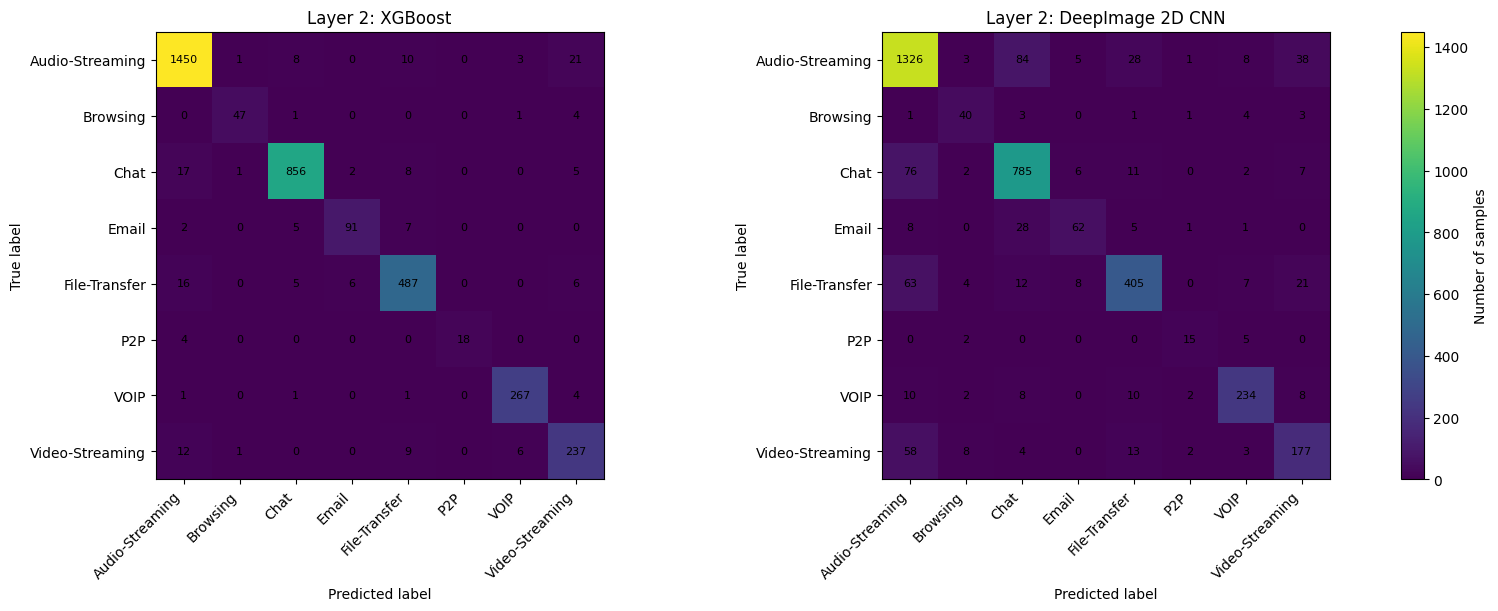

In [18]:
models = ["XGBoost", "DeepImage 2D CNN"]
matrices = [
    confusion_matrix(layer2.y_test, predictions[("Layer2", model_name)])
    for model_name in models
]

vmax = max(matrix.max() for matrix in matrices)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)

for ax, model_name, matrix in zip(axes, models, matrices):
    image = ax.imshow(matrix, vmin=0, vmax=vmax)
    ax.set_title(f"Layer 2: {model_name}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(len(layer2.class_names)))
    ax.set_yticks(range(len(layer2.class_names)))
    ax.set_xticklabels(layer2.class_names, rotation=45, ha="right")
    ax.set_yticklabels(layer2.class_names)

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center", fontsize=8)

fig.colorbar(image, ax=axes, label="Number of samples")
plt.show()


## Feature Locality Analysis


In [19]:
task = layer2
N_RANDOM_LAYOUTS = 5
LOCALITY_MAX_EPOCHS = 120
LOCALITY_PATIENCE = 10
LOCALITY_BATCH_SIZE = 256

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(task.X_train_tree).astype("float32")
X_test = scaler.transform(task.X_test_tree).astype("float32")
y_train = np.asarray(task.y_train)
y_test = np.asarray(task.y_test)
n_features = X_train.shape[1]

indices = np.arange(len(X_train))
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train,
)

def make_grid(values, feature_order):
    ordered = values[:, feature_order]
    padded = np.pad(
        ordered,
        ((0, 0), (0, 64 - ordered.shape[1])),
        mode="constant",
    )
    return padded.reshape(-1, 8, 8, 1)

def get_correlation_order(values):
    corr = pd.DataFrame(values).corr(method="spearman").abs().fillna(0)
    np.fill_diagonal(corr.values, 1.0)

    distance = 1.0 - corr.values
    distance = (distance + distance.T) / 2.0
    np.fill_diagonal(distance, 0.0)

    tree = linkage(squareform(distance, checks=False), method="average")
    return leaves_list(tree)

locality_rows = []

def run_layout(layout_name, feature_order):
    tf.keras.backend.clear_session()
    gc.collect()
    set_all_seeds(SEED)

    X_train_grid = make_grid(X_train, feature_order)
    X_test_grid = make_grid(X_test, feature_order)

    model = build_deepimage_cnn(len(task.class_names))
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=LOCALITY_PATIENCE,
            restore_best_weights=True,
            verbose=0,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=4,
            min_lr=1e-6,
            verbose=0,
        ),
    ]

    history = model.fit(
        X_train_grid[train_idx],
        y_train[train_idx],
        validation_data=(X_train_grid[val_idx], y_train[val_idx]),
        epochs=LOCALITY_MAX_EPOCHS,
        batch_size=LOCALITY_BATCH_SIZE,
        callbacks=callbacks,
        verbose=0,
    )

    pred = model.predict(X_test_grid, batch_size=1024, verbose=0).argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        pred,
        average="macro",
        zero_division=0,
    )

    row = {
        "Experiment": layout_name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Epochs": len(history.history["loss"]),
    }
    locality_rows.append(row)
    print(layout_name, f"Macro-F1={f1:.4f}")

run_layout("CNN - Importance-ordered layout", np.arange(n_features))

for trial in range(N_RANDOM_LAYOUTS):
    rng = np.random.default_rng(SEED + 1000 + trial)
    run_layout(
        f"CNN - Random layout {trial + 1}",
        rng.permutation(n_features),
    )

correlation_order = get_correlation_order(X_train[train_idx])
run_layout("CNN - Correlation-based layout", correlation_order)

tf.keras.backend.clear_session()
gc.collect()
set_all_seeds(SEED)

mlp = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.20),
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.20),
    layers.Dense(32, activation="relu"),
    layers.Dense(len(task.class_names), activation="softmax"),
])

mlp.compile(
    optimizer=keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=LOCALITY_PATIENCE,
        restore_best_weights=True,
        verbose=0,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=0,
    ),
]

mlp_history = mlp.fit(
    X_train[train_idx],
    y_train[train_idx],
    validation_data=(X_train[val_idx], y_train[val_idx]),
    epochs=LOCALITY_MAX_EPOCHS,
    batch_size=LOCALITY_BATCH_SIZE,
    callbacks=callbacks,
    verbose=0,
)

mlp_pred = mlp.predict(X_test, batch_size=1024, verbose=0).argmax(axis=1)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test,
    mlp_pred,
    average="macro",
    zero_division=0,
)

locality_rows.append({
    "Experiment": "MLP - No spatial layout",
    "Accuracy": accuracy_score(y_test, mlp_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, mlp_pred),
    "Macro Precision": precision,
    "Macro Recall": recall,
    "Macro F1": f1,
    "Epochs": len(mlp_history.history["loss"]),
})

locality_raw_df = pd.DataFrame(locality_rows)
random_rows = locality_raw_df[
    locality_raw_df["Experiment"].str.contains("Random layout")
]

importance_row = locality_raw_df[
    locality_raw_df["Experiment"].eq("CNN - Importance-ordered layout")
].iloc[0]

correlation_row = locality_raw_df[
    locality_raw_df["Experiment"].eq("CNN - Correlation-based layout")
].iloc[0]

mlp_row = locality_raw_df[
    locality_raw_df["Experiment"].eq("MLP - No spatial layout")
].iloc[0]

random_summary = {
    "Experiment": "CNN - Random layouts (mean)",
    "Accuracy": random_rows["Accuracy"].mean(),
    "Balanced Accuracy": random_rows["Balanced Accuracy"].mean(),
    "Macro Precision": random_rows["Macro Precision"].mean(),
    "Macro Recall": random_rows["Macro Recall"].mean(),
    "Macro F1": random_rows["Macro F1"].mean(),
    "Epochs": random_rows["Epochs"].mean(),
}

final_locality_df = pd.DataFrame([
    importance_row.to_dict(),
    random_summary,
    correlation_row.to_dict(),
    mlp_row.to_dict(),
])

display(
    final_locality_df.style.format({
        "Accuracy": "{:.4f}",
        "Balanced Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Epochs": "{:.1f}",
    })
)

print(
    "Random-layout Macro-F1 standard deviation:",
    f"{random_rows['Macro F1'].std():.4f}",
)
print(
    "Importance minus random-mean Macro-F1:",
    f"{importance_row['Macro F1'] - random_rows['Macro F1'].mean():+.4f}",
)
print(
    "Importance minus best-random Macro-F1:",
    f"{importance_row['Macro F1'] - random_rows['Macro F1'].max():+.4f}",
)


CNN - Importance-ordered layout Macro-F1=0.7858
CNN - Random layout 1 Macro-F1=0.7831
CNN - Random layout 2 Macro-F1=0.7832
CNN - Random layout 3 Macro-F1=0.7615
CNN - Random layout 4 Macro-F1=0.7837
CNN - Random layout 5 Macro-F1=0.7852
CNN - Correlation-based layout Macro-F1=0.7812


,Experiment,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Epochs
0,CNN - Importance-ordered layout,0.8478,0.7826,0.7935,0.7826,0.7858,120.0
1,CNN - Random layouts (mean),0.8404,0.7726,0.7955,0.7726,0.7793,120.0
2,CNN - Correlation-based layout,0.8498,0.7699,0.7983,0.7699,0.7812,120.0
3,MLP - No spatial layout,0.8509,0.7788,0.7662,0.7788,0.7705,114.0


Random-layout Macro-F1 standard deviation: 0.0100
Importance minus random-mean Macro-F1: +0.0065
Importance minus best-random Macro-F1: +0.0007


## Export Results


In [20]:
OUTPUT_DIR = Path("/content/didarknet_results")
OUTPUT_DIR.mkdir(exist_ok=True)

results_df.to_csv(OUTPUT_DIR / "all_model_results.csv", index=False)
comparison_df.to_csv(OUTPUT_DIR / "comparison_vs_cnn.csv", index=False)
paper_comparison.to_csv(OUTPUT_DIR / "paper_reproduction_comparison.csv", index=False)
locality_raw_df.to_csv(OUTPUT_DIR / "feature_locality_raw.csv", index=False)
final_locality_df.to_csv(OUTPUT_DIR / "feature_locality_summary.csv", index=False)
layer1.feature_importance.to_csv(OUTPUT_DIR / "layer1_feature_importance.csv", index=False)
layer2.feature_importance.to_csv(OUTPUT_DIR / "layer2_feature_importance.csv", index=False)

print("Saved results to:", OUTPUT_DIR)


Saved results to: /content/didarknet_results
